In [ ]:
import nflreadpy as nfl
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import numpy as np

# 1. Load Next Gen Stats receiving data (2023-2025) 
raw_ngs = nfl.load_nextgen_stats([2023, 2024, 2025], stat_type='receiving')
df_ngs = raw_ngs.to_pandas() if hasattr(raw_ngs, 'to_pandas') else raw_ngs.copy()

# Export original source dataset for safe-keeping (no need to uncomment this)
# df_ngs.to_csv("raw_ngs_receiving_2023_2025.csv", index=False)

# Filter to keep regular season games AND exclude full-season summary rows (week == 0)
df_ngs_reg = df_ngs[(df_ngs['season_type'] == 'REG') & (df_ngs['week'] != 0)].copy()

# 2. Sum total targets across unique player IDs
player_totals = df_ngs_reg.groupby('player_gsis_id', as_index=False).agg(
    player_display_name=('player_display_name', 'first'),
    total_targets=('targets', 'sum')
)

In [141]:
# 3. Calculate target-weighted averages for the 3 spatial tracking features
spatial_features = ['avg_intended_air_yards', 'avg_cushion', 'avg_yac_above_expectation']

for col in spatial_features:
    weighted_col = (
        df_ngs_reg.groupby('player_gsis_id')
        .apply(lambda g: (g[col] * g['targets']).sum() / g['targets'].sum() if g['targets'].sum() > 0 else None)
        .reset_index(name=col)
    )
    player_totals = player_totals.merge(weighted_col, on='player_gsis_id')

In [142]:
# 4. Filter for minimum sample size (>= 75 targets) and drop NaNs
df_3feat = player_totals[player_totals['total_targets'] >= 75].dropna().copy()

# 5. Standardize the 3-feature matrix
scaler = StandardScaler()
X_scaled_3 = scaler.fit_transform(df_3feat[spatial_features])

C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\clust

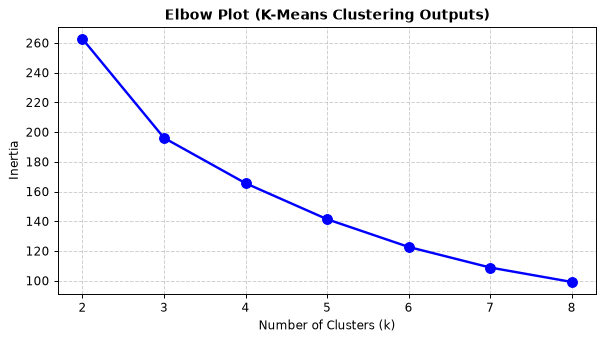

C:\Users\samue\Documents\SeansFiles\CondaNav\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [143]:
# 6. Run and Plot the Elbow Method (Inertia) across k = 2 to 8
k_range = range(2, 9)
inertia_scores = []

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled_3)
    inertia_scores.append(kmeans.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(k_range, inertia_scores, 'bo-', linewidth=2, markersize=8)
plt.title('Elbow Plot (K-Means Clustering Outputs)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Clusters (k)', fontsize=10)
plt.ylabel('Inertia', fontsize=10)
plt.xticks(k_range)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

# 7. Fit final KMeans model for k=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
df_3feat['cluster'] = kmeans_5.fit_predict(X_scaled_3)

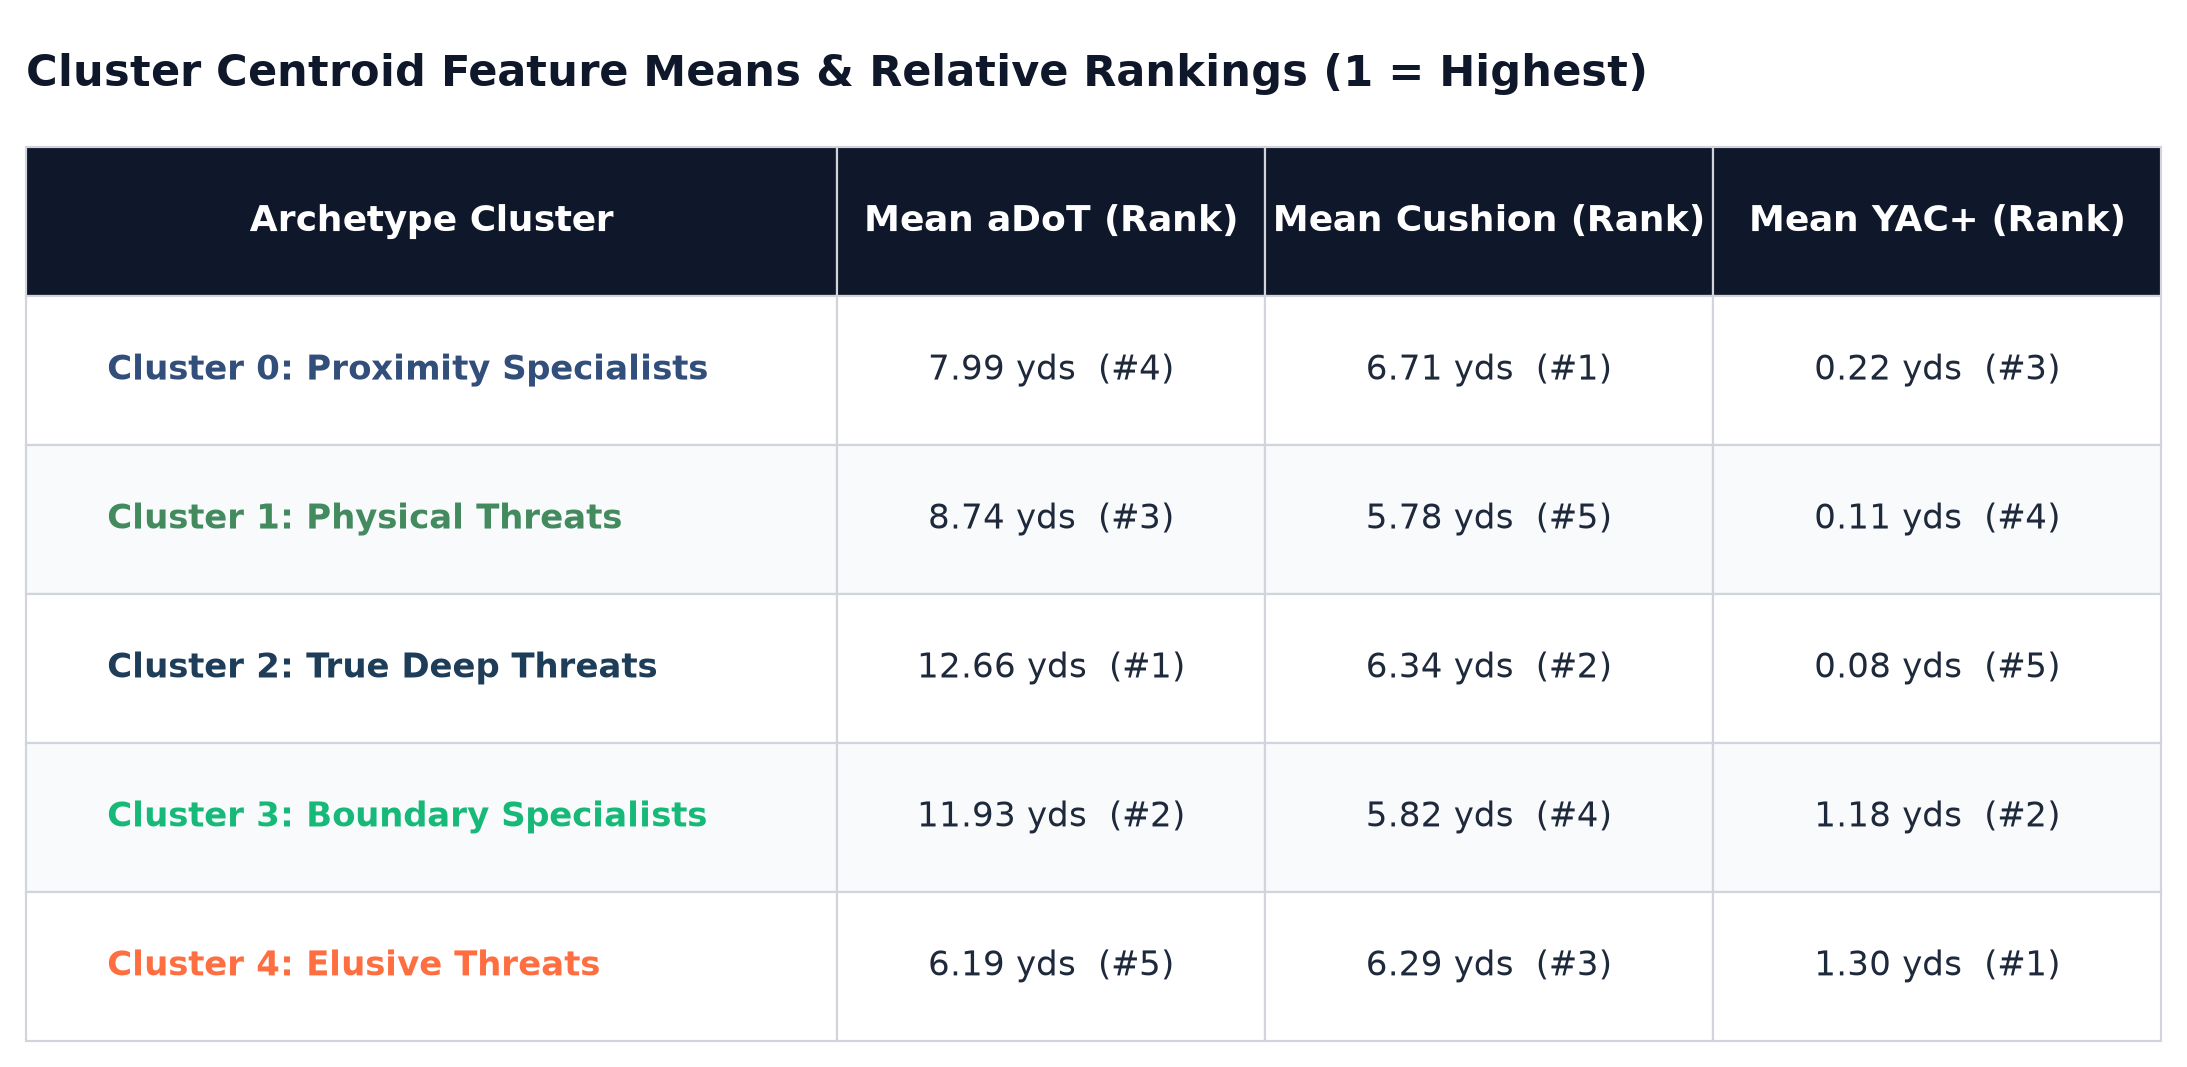

In [144]:
#8. Summarize each cluster in terms of the features of its centroid

# Compute Centroid Means and Relative Ranks directly from your clustering DataFrame
spatial_features = ['avg_intended_air_yards', 'avg_cushion', 'avg_yac_above_expectation']

centroid_means = df_3feat.groupby('cluster')[spatial_features].mean().rename(columns={
    'avg_intended_air_yards': 'aDoT',
    'avg_cushion': 'Cushion',
    'avg_yac_above_expectation': 'YAC+'
})

# Calculate relative rank across the 5 centroids (1 = Highest value, 5 = Lowest value)
centroid_ranks = centroid_means.rank(ascending=False, method='min').astype(int)

# Map Archetype Name Metadata & Brand Colors
cluster_names = {
    0: "Cluster 0: Proximity Specialists",
    1: "Cluster 1: Physical Threats",
    2: "Cluster 2: True Deep Threats",
    3: "Cluster 3: Boundary Specialists",
    4: "Cluster 4: Elusive Threats"
}

cluster_colors = {
    0: '#324e7b',  # Steel Blue
    1: '#438a5e',  # Forest Green
    2: '#1e3d59',  # Deep Navy
    3: '#17b978',  # Emerald Alpha
    4: '#ff6e40'   # Burst Orange
}

# Format qualitative cell text string: "Mean (Rank)"
table_data = []
for c in range(5):
    adot_str = f"{centroid_means.loc[c, 'aDoT']:.2f} yds  (#{centroid_ranks.loc[c, 'aDoT']})"
    cush_str = f"{centroid_means.loc[c, 'Cushion']:.2f} yds  (#{centroid_ranks.loc[c, 'Cushion']})"
    yac_str  = f"{centroid_means.loc[c, 'YAC+']:.2f} yds  (#{centroid_ranks.loc[c, 'YAC+']})"
    
    table_data.append([cluster_names[c], adot_str, cush_str, yac_str])

# Construct Canvas & Table Grid
fig, ax = plt.subplots(figsize=(8.5, 4.2), dpi=300)
ax.axis('off')

col_labels = ['Archetype Cluster', 'Mean aDoT (Rank)', 'Mean Cushion (Rank)', 'Mean YAC+ (Rank)']

table = ax.table(
    cellText=table_data,
    colLabels=col_labels,
    colWidths=[0.38, 0.20, 0.21, 0.21],
    cellLoc='center',
    bbox=[0.0, 0.0, 1.0, 0.88]
)

table.auto_set_font_size(False)
table.set_fontsize(9.5)

# Apply Custom Styling (Zebra Striping, Brand Borders & Alignment)
for (row_idx, col_idx), cell in table.get_celld().items():
    cell.set_edgecolor('#d1d5db')
    cell.set_linewidth(0.6)
    
    # Header Row
    if row_idx == 0:
        cell.set_facecolor('#0f172a')  # Dark Slate Banner
        cell.get_text().set_color('white')
        cell.get_text().set_weight('bold')
        cell.get_text().set_fontsize(10)
    # Roster Data Rows
    else:
        cluster_id = row_idx - 1
        bg_color = '#ffffff' if row_idx % 2 != 0 else '#f8fafc'
        cell.set_facecolor(bg_color)
        
        # Archetype Name Column: Left-align & color-code badge accent
        if col_idx == 0:
            cell.get_text().set_ha('left')
            cell.get_text().set_weight('bold')
            cell.get_text().set_color(cluster_colors[cluster_id])
            cell.get_text().set_position((cell.get_text().get_position()[0] - 0.35, cell.get_text().get_position()[1]))
        else:
            cell.get_text().set_color('#1e293b')

# Add Graphic Title Banner
ax.text(
    0.0, 0.93, "Cluster Centroid Feature Means & Relative Rankings (1 = Highest)",
    transform=ax.transAxes,
    fontsize=12,
    fontweight='bold',
    color='#0f172a',
    ha='left',
    va='bottom'
)

plt.tight_layout()
plt.show()

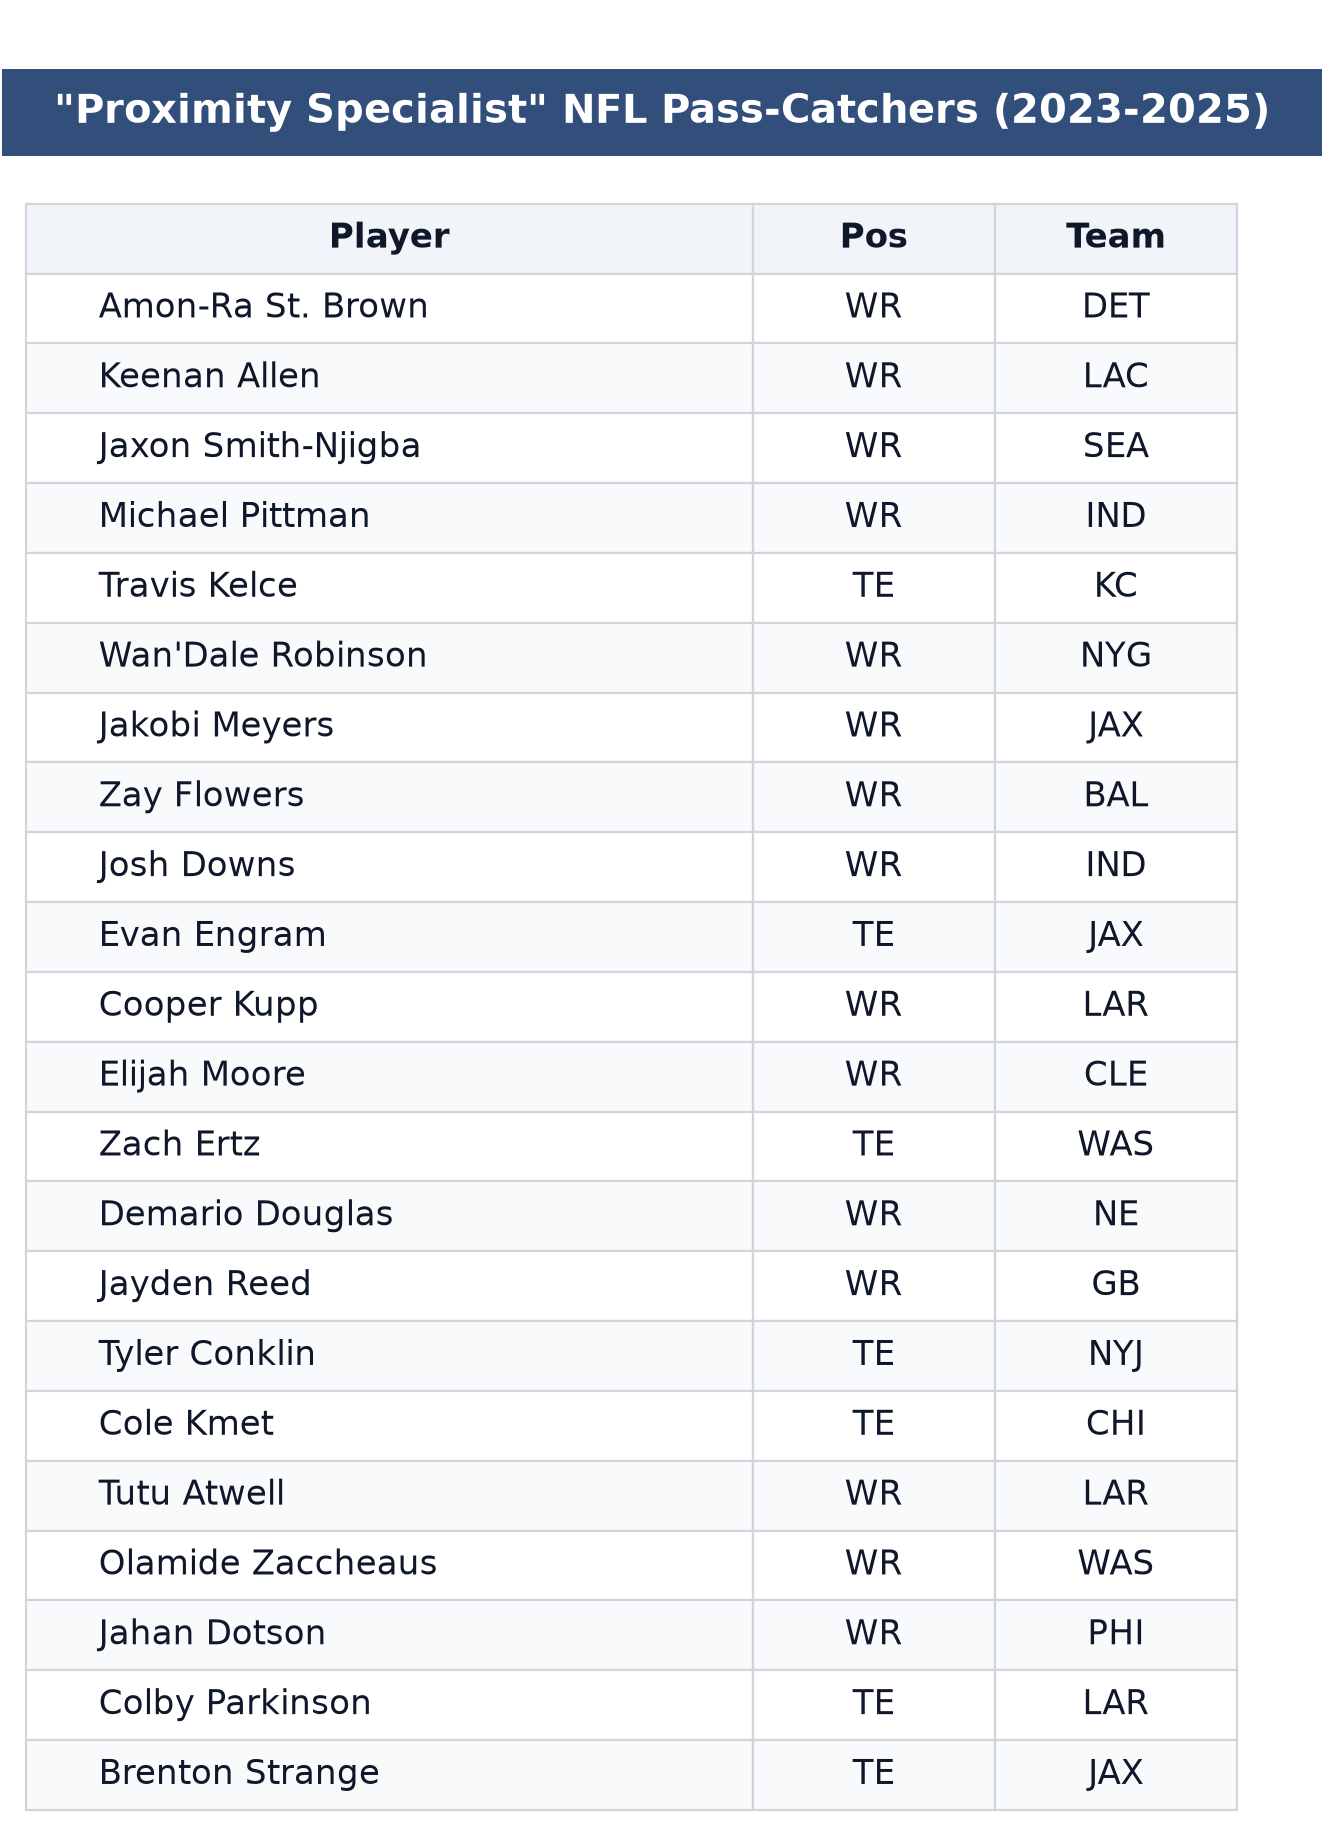

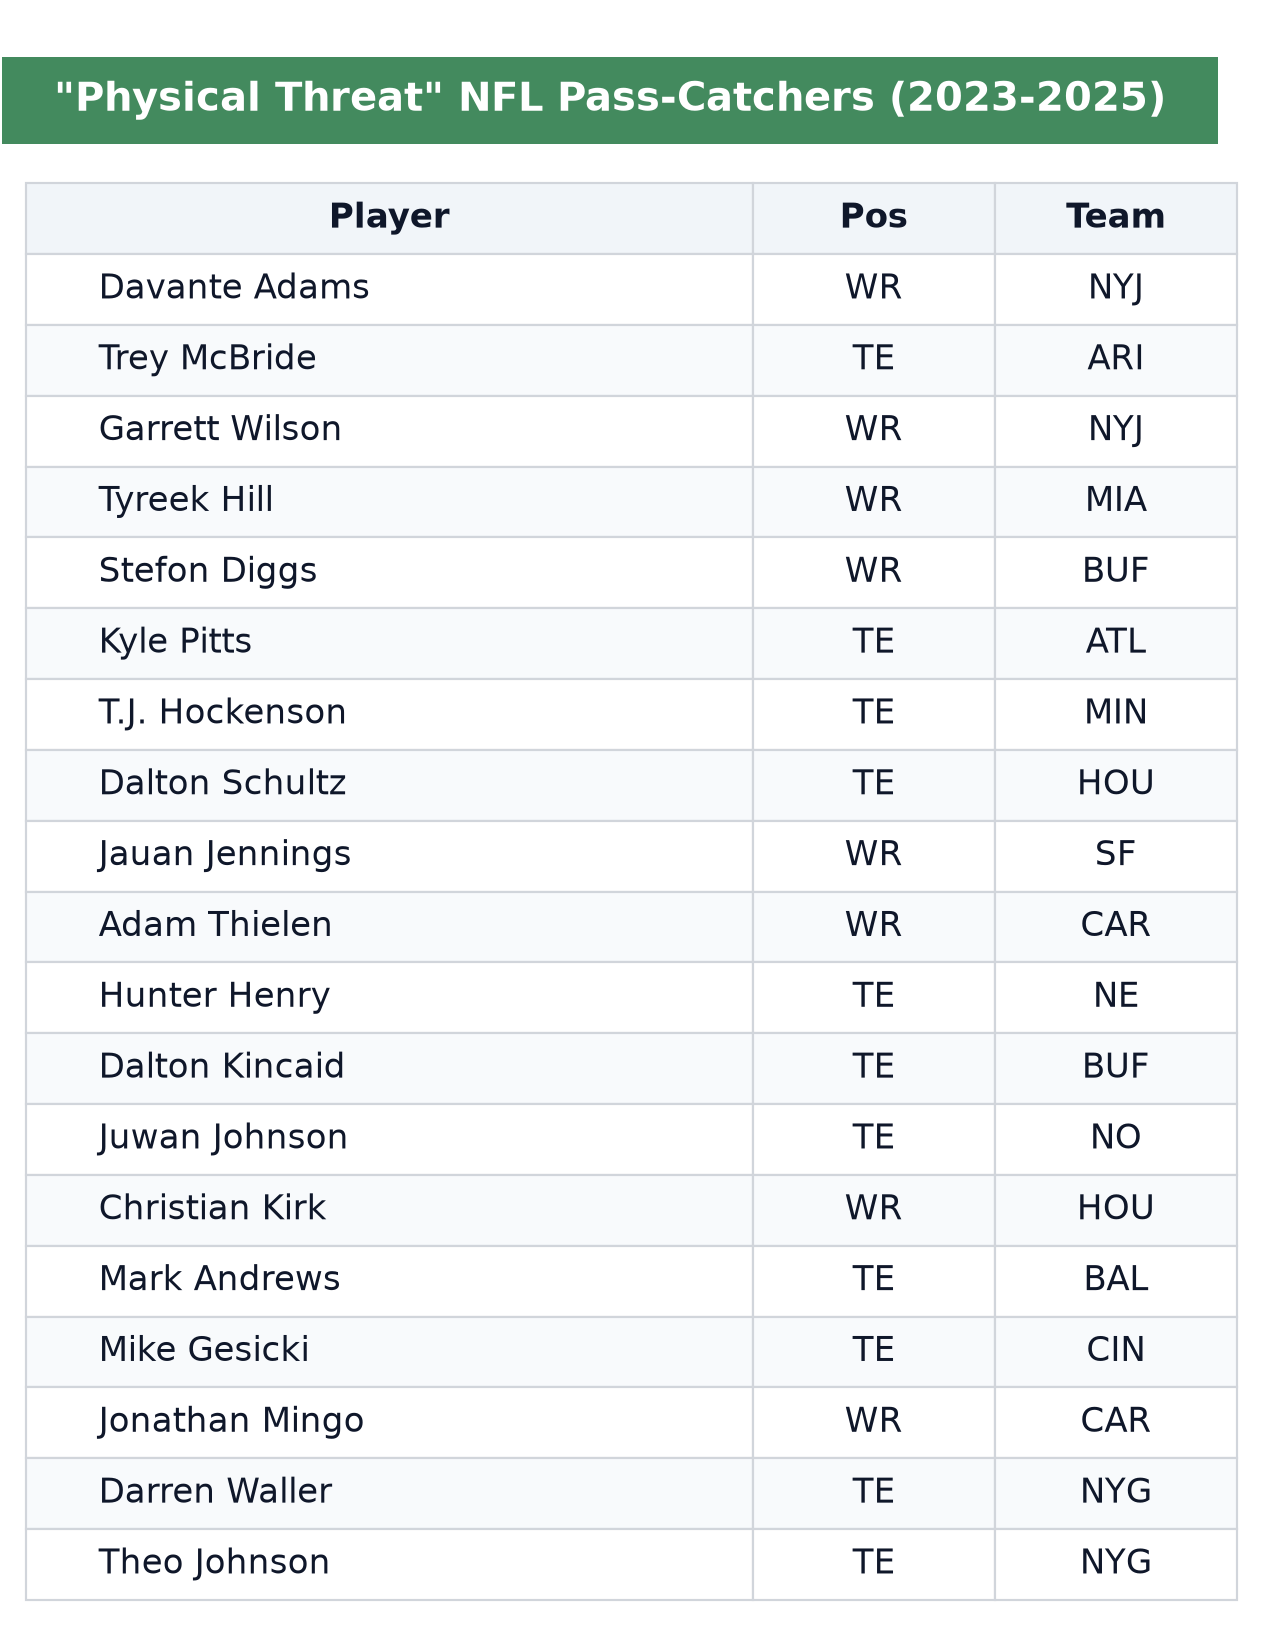

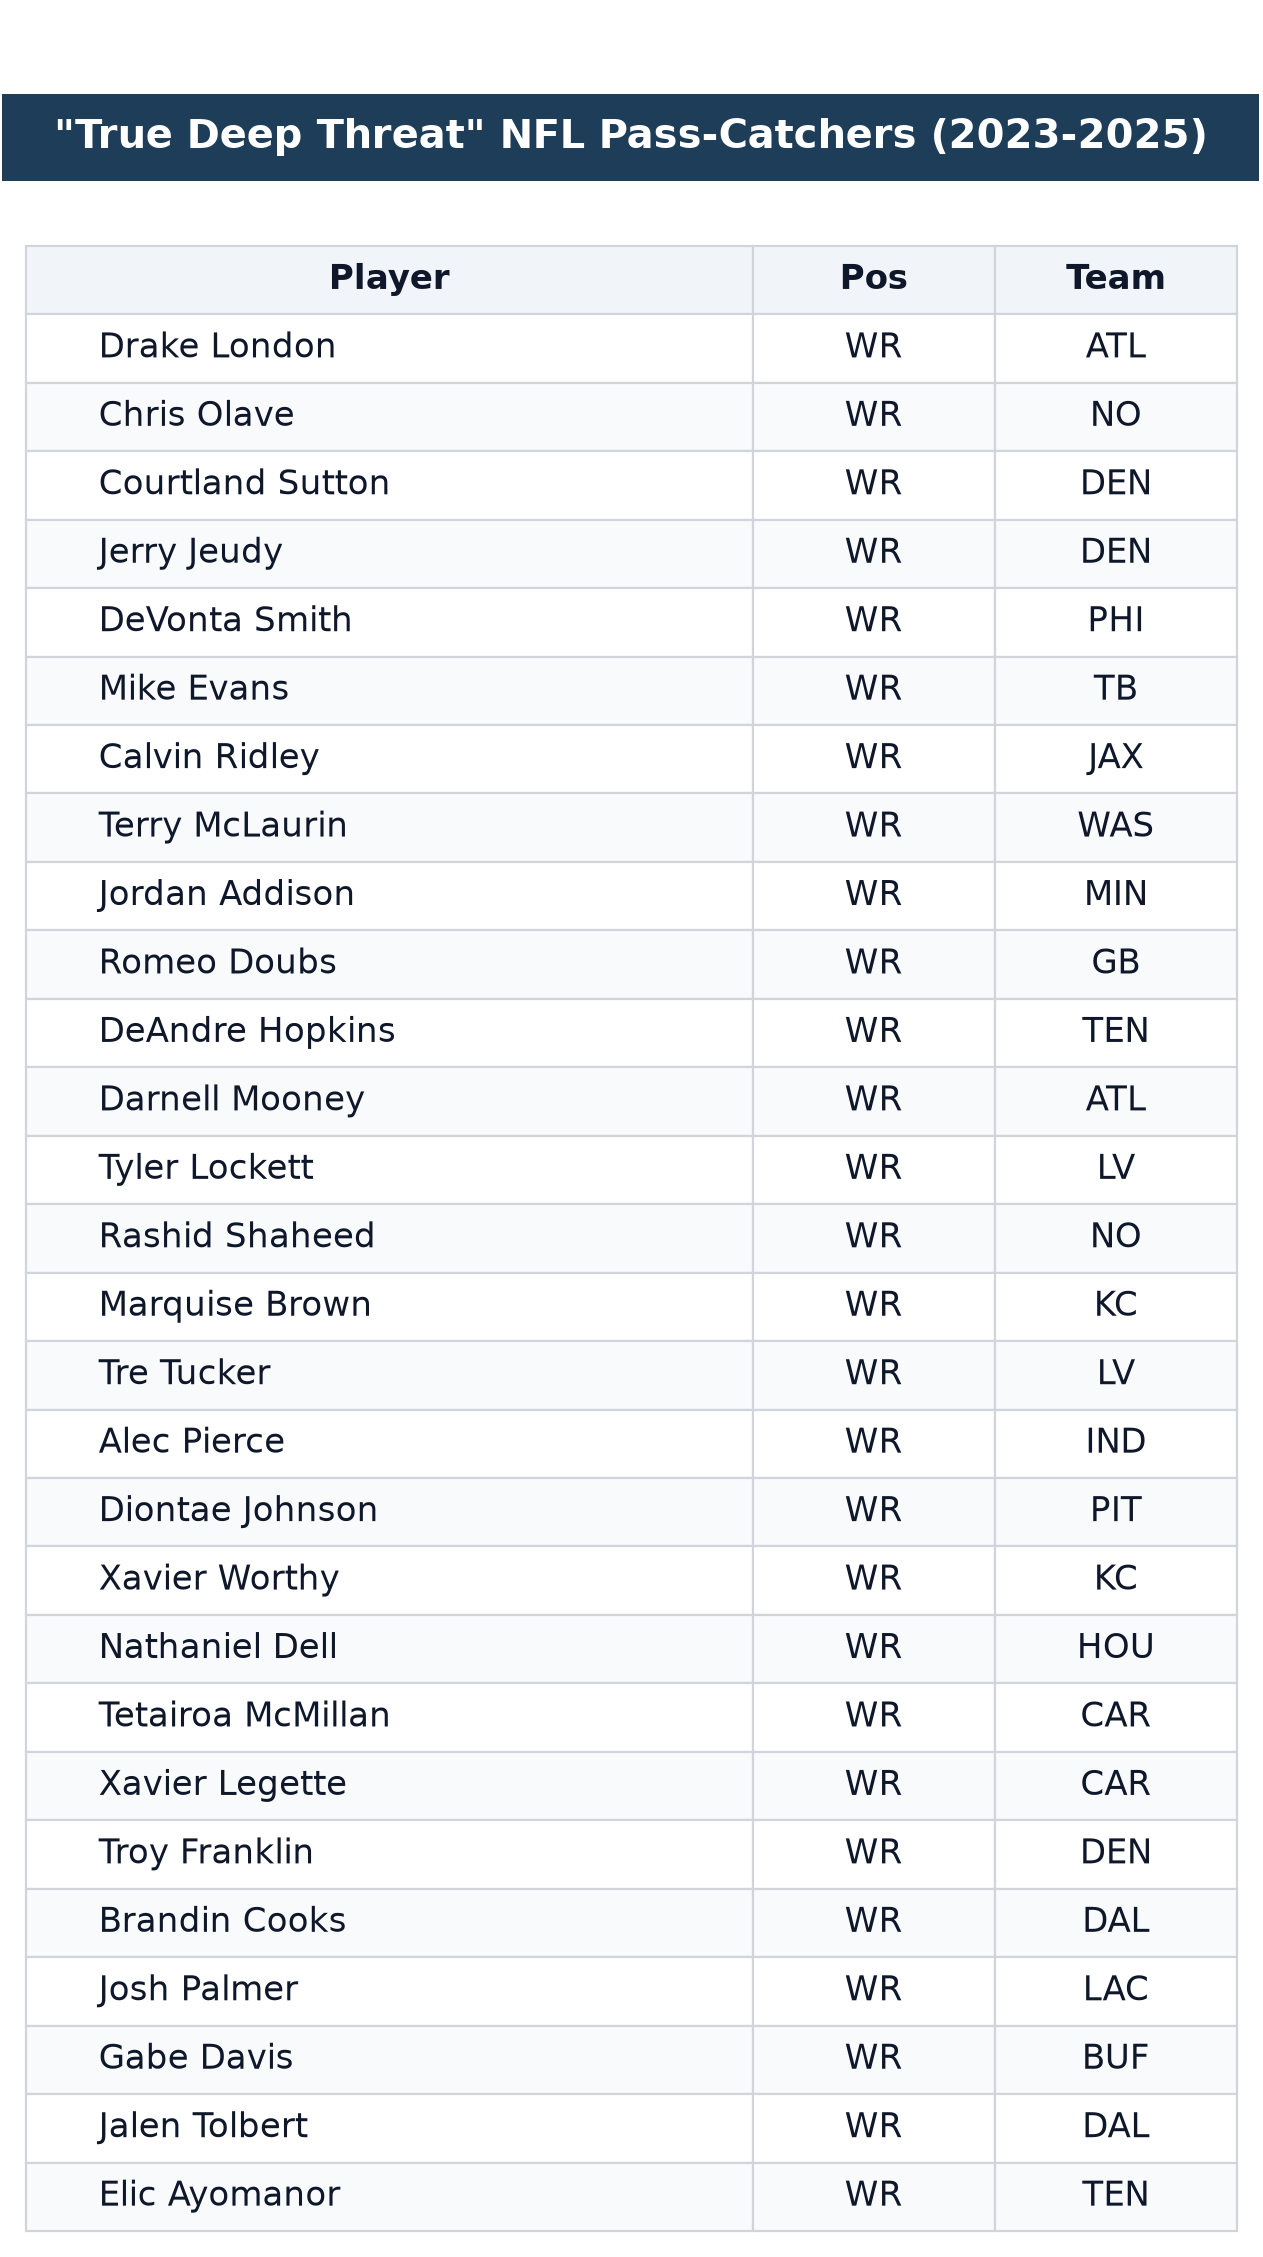

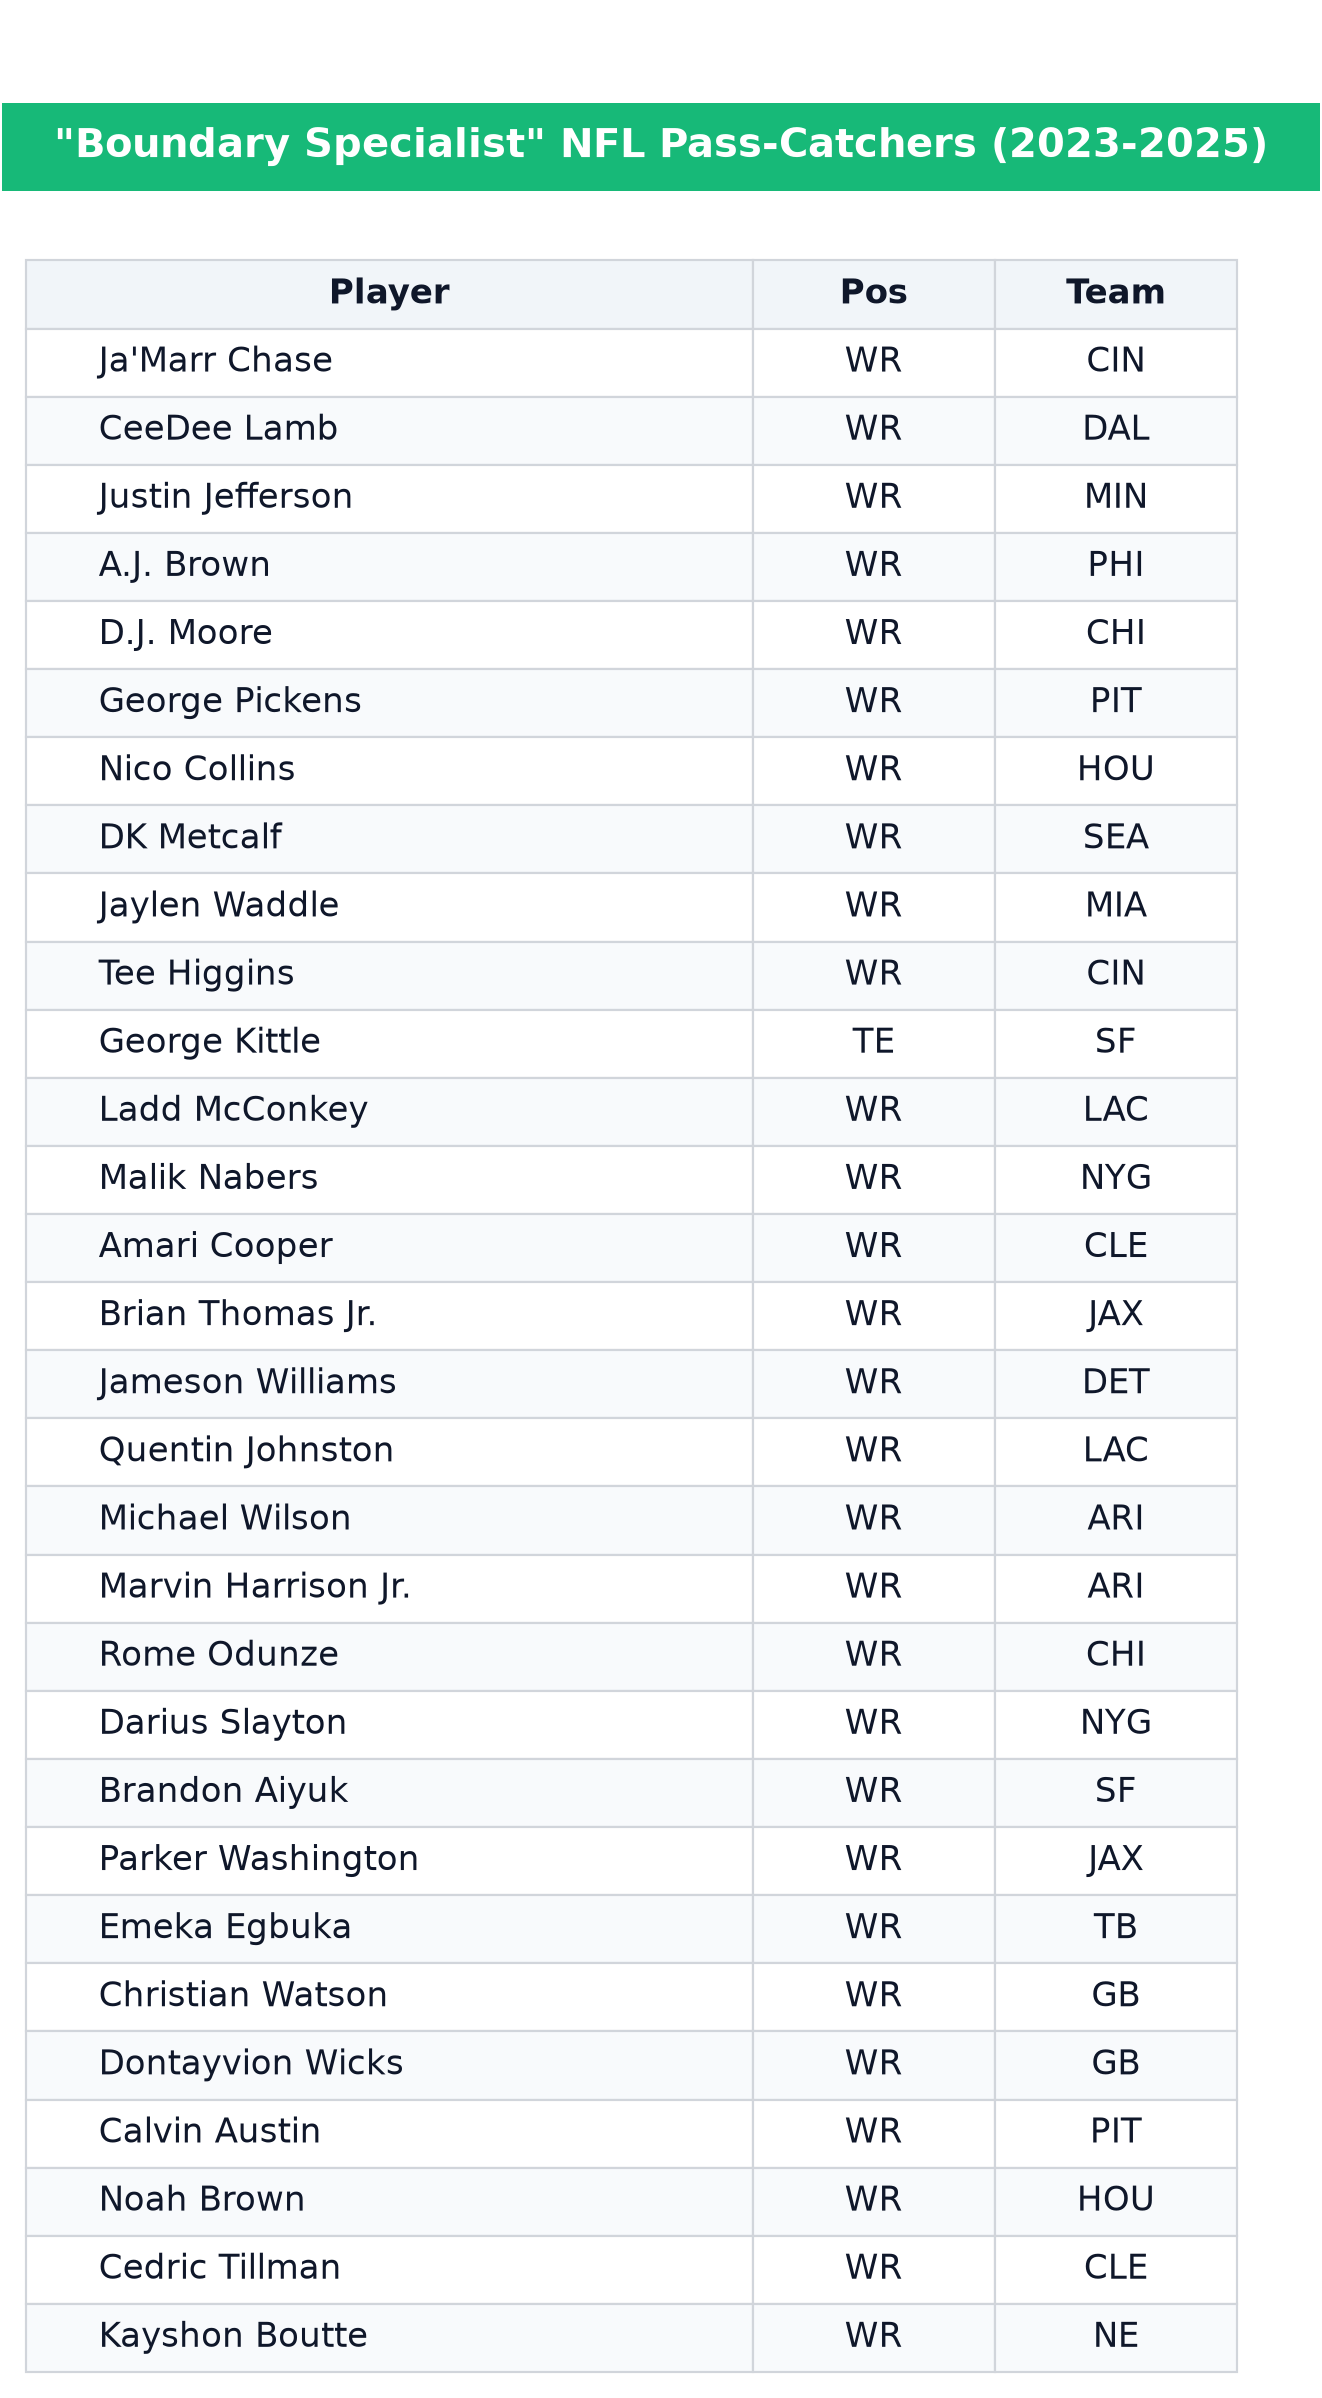

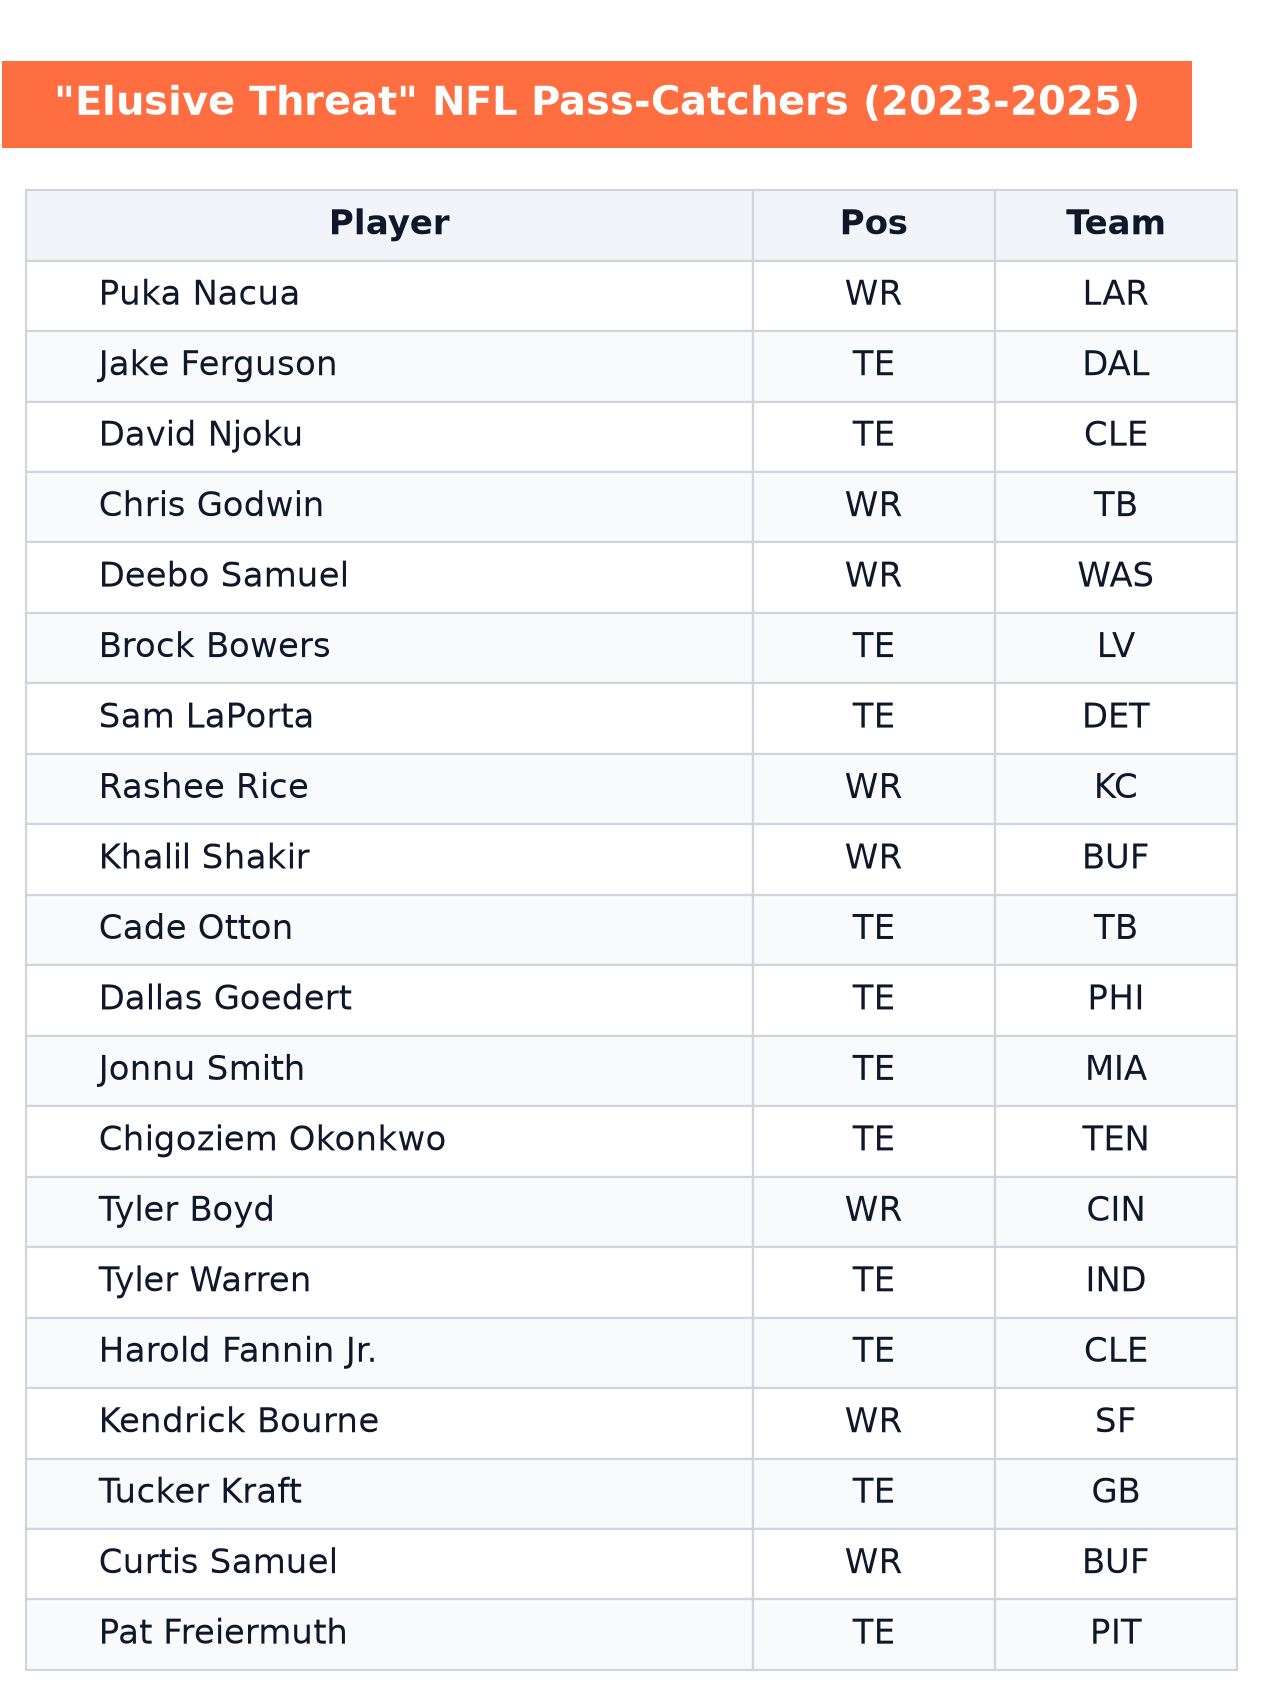

In [145]:
# 9. Print out final cluster (player archetype) assignments

# Dynamically resolve Team and Position column names from df_ngs_reg
team_col = 'recent_team' if 'recent_team' in df_ngs_reg.columns else ('team_abbr' if 'team_abbr' in df_ngs_reg.columns else 'team')
pos_col = 'player_position' if 'player_position' in df_ngs_reg.columns else ('position' if 'position' in df_ngs_reg.columns else 'pos')

meta_df = df_ngs_reg.sort_values('week').groupby('player_gsis_id', as_index=False).last()[
    ['player_gsis_id', team_col, pos_col]
].rename(columns={team_col: 'recent_team', pos_col: 'player_position'})

df_3feat_meta = df_3feat.merge(meta_df, on='player_gsis_id', how='left')

# Cluster Titles and Color Palette
cluster_labels = {
    0: "\"Proximity Specialist\" NFL Pass-Catchers (2023-2025)",
    1: "\"Physical Threat\" NFL Pass-Catchers (2023-2025)",
    2: "\"True Deep Threat\" NFL Pass-Catchers (2023-2025)",
    3: "\"Boundary Specialist\" NFL Pass-Catchers (2023-2025)",
    4: "\"Elusive Threat\" NFL Pass-Catchers (2023-2025)"
}

cluster_colors = {
    0: '#324e7b',  # Steel Blue
    1: '#438a5e',  # Forest Green
    2: '#1e3d59',  # Deep Navy
    3: '#17b978',  # Emerald Alpha
    4: '#ff6e40'   # Burst Orange
}

# Generate 5 Clean Roster Tables
for c in range(5):
    c_df = df_3feat_meta[df_3feat_meta['cluster'] == c].sort_values('total_targets', ascending=False).copy()
    
    display_df = pd.DataFrame({
        'Player': c_df['player_display_name'],
        'Pos': c_df['player_position'],
        'Team': c_df['recent_team']
    })
    
    num_players = len(display_df)
    
    # Linear height scaling: ~0.35 inches per player row + padding for title/headers
    fig_height = max(3.0, num_players * 0.35 + 1.2)
    fig, ax = plt.subplots(figsize=(6, fig_height), dpi=300)
    ax.axis('off')
    
    # Render table filling the lower portion of the figure (y from 0.0 to 0.90)
    # Using bbox=[x0, y0, width, height] prevents Matplotlib cell height squishing!
    table_height = min(0.88, num_players * 0.038 + 0.06)
    table = ax.table(
        cellText=display_df.values,
        colLabels=display_df.columns,
        colWidths=[0.60, 0.20, 0.20],
        cellLoc='center',
        bbox=[0.0, 0.0, 1.0, 0.90]  # Locks table neatly from y=0 to y=0.90
    )
    
    table.auto_set_font_size(False)
    table.set_fontsize(9.5)
    
    header_color = cluster_colors[c]
    
    # Format table cells
    for (row_idx, col_idx), cell in table.get_celld().items():
        cell.set_edgecolor('#d1d5db')
        cell.set_linewidth(0.6)
        
        # Column Header Row (Player, Pos, Team)
        if row_idx == 0:
            cell.set_facecolor('#f1f5f9')
            cell.get_text().set_color('#0f172a')
            cell.get_text().set_weight('bold')
            cell.get_text().set_fontsize(9.5)
        # Data Rows
        else:
            bg_color = '#ffffff' if row_idx % 2 != 0 else '#f8fafc'
            cell.set_facecolor(bg_color)
            cell.get_text().set_color('#0f172a')
            
            # Left-align player names, center Pos/Team
            if col_idx == 0:
                cell.get_text().set_ha('left')
                cell.get_text().set_position((cell.get_text().get_position()[0] - 0.40, cell.get_text().get_position()[1]))
    
    # Draw Header Banner anchored at top (y=0.93 to 1.0)
    title_text = f"  {cluster_labels[c]}  "
    
    ax.text(
        0.0, 0.94, title_text,
        transform=ax.transAxes,
        fontsize=11,
        fontweight='bold',
        color='white',
        verticalalignment='bottom',
        horizontalalignment='left',
        bbox=dict(
            boxstyle='square,pad=0.6',
            facecolor=header_color,
            edgecolor='none'
        )
    )
    
    plt.show()